# Avance 1: Diseño del estudio y relaciones entre variables

**Proyecto:** Determinantes de las hospitalizaciones prolongadas en beneficiarios FONASA (Chile, 2020)

Este notebook sigue los cinco puntos que pide la pauta del Avance 1:

1. Pregunta de investigación e hipótesis
2. Revisión de literatura
3. Metodología
4. Diagrama metodológico
5. Análisis de relaciones entre variables

## 1. Pregunta de investigación

**Contexto.** Unas pocas hospitalizaciones muy largas ocupan gran parte de las camas. En los egresos FONASA de 2020, las estadías de más de 15 días fueron el 9,4 % de los egresos, pero usaron el 47,1 % de los días-cama (lo calculamos en la sección 5). Conocer qué se asocia a esas estadías ayuda a planificar camas.

**Pregunta:**

> ¿Qué factores clínicos, demográficos y del sistema de salud se asocian con la duración de la estadía y con las estadías prolongadas (más de 15 días) en los egresos FONASA de Chile en 2020?

Definimos como **prolongada** una estadía de más de 15 días, porque 15 días es el percentil 90 de la duración.

**Hipótesis general:**

- **H₀:** la duración de la estadía no se asocia con los factores clínicos, demográficos ni del sistema de salud.
- **H₁:** al menos uno de esos factores se asocia con la duración de la estadía.

**Hipótesis específicas** (una por grupo de factores):

| | Factores | H₁ |
|---|---|---|
| H1a | Clínicos: capítulo del diagnóstico (CIE-10) y cirugía | Se asocian a la duración |
| H1b | Demográficos: edad, sexo, nacionalidad y etnia | Se asocian a la duración (esperamos más días a mayor edad) |
| H1c | Sistema de salud: tipo de establecimiento y región | Se asocian a la duración |

## 2. Revisión de literatura

**El diagnóstico no lo explica todo.** Los Grupos Relacionados por el Diagnóstico (GRD) agrupan pacientes según diagnóstico y procedimiento, porque estos explican buena parte de los recursos y de la duración de la estadía (Fetter et al., 1980). Sin embargo, Freitas et al. (2012), con 9 millones de hospitalizaciones en Portugal, encontraron que la edad y el tipo de hospital seguían asociados a las estadías extremas, aun dentro de un mismo GRD. Por eso incluimos factores del paciente y del establecimiento, no solo el diagnóstico.

**Cómo se modela.** La revisión de Lequertier et al. (2021) muestra que la regresión es el método más usado para predecir la duración de la estadía. Esto respalda usar regresión múltiple en el Avance 2.

**Muestras grandes.** Con casi un millón de registros, casi cualquier diferencia sale significativa. Lin et al. (2013) recomiendan reportar el tamaño del efecto junto al valor-p, y lo interpretamos con los umbrales de Cohen (1988).

**Gap.** En Chile, Olivares-Tirado (2020) estudió las estadías largas solo en adultos mayores. No encontramos un estudio que analice juntos factores clínicos, demográficos y del sistema de salud en todos los egresos FONASA, ni para 2020, el primer año de la pandemia.

## 3. Metodología

**Tipo de análisis:**

- Descriptivo: cómo se distribuye la duración.
- Inferencial: pruebas de hipótesis de la sección 5.
- Predictivo: regresión múltiple en el Avance 2.

**Datos:**

| | |
|---|---|
| Fuente | DEIS-MINSAL, egresos hospitalarios 2020 (datos abiertos) |
| Filtro | Solo FONASA y estadías de hasta 365 días (las más largas son errores de registro) |
| Registros | 968.098 egresos (dentro del rango pedido de 700.000 a 1.000.000) |
| Unidad de análisis | Cada egreso hospitalario |
| Período | Año 2020 |

**Variables seleccionadas.** La base tiene 18 columnas. Elegimos las que (1) se conocen al ingresar el paciente, (2) tienen una razón para afectar la duración y (3) no repiten a otra columna.

| Variable | Columna | Tipo | Por qué |
|---|---|---|---|
| Días de estada | `DIAS_ESTADA` | Numérica | Respuesta de la regresión lineal |
| Estadía prolongada | `DIAS_ESTADA` > 15 | Categórica (Sí/No) | Respuesta de la regresión logística |
| Capítulo CIE-10 | `DIAG1` | Categórica (21) | Aproxima la gravedad del caso, porque la base no trae el peso GRD |
| Cirugía | `INTERV_Q` | Categórica (Sí/No) | Distingue casos quirúrgicos de médicos |
| Edad | `GRUPO_EDAD` | Numérica (punto medio del tramo) | Más edad, más días (Freitas et al., 2012) |
| Sexo | `SEXO` | Categórica | Variable demográfica básica |
| Nacionalidad | `GLOSA_PAIS_ORIGEN` | Categórica (Chilena/Extranjera) | Posibles diferencias de acceso |
| Etnia | `ETNIA` | Categórica (Sí/No) | Posibles diferencias de acceso |
| Establecimiento | `PERTENENCIA_ESTABLECIMIENTO_SALUD` | Categórica (Público SNSS/No SNSS) | El tipo de hospital se asocia a estadías largas (Freitas et al., 2012) |
| Región | `REGION_RESIDENCIA` | Categórica (16) | La oferta de camas cambia entre regiones |

**Columnas descartadas:** `CONDICION_EGRESO` (vivo o fallecido) se conoce recién al final de la hospitalización. `DIAG2` (causa externa) solo aparece cuando el diagnóstico es un traumatismo, así que repite el capítulo. `PROCED` no está descrita en el diccionario. La comuna (344 valores) queda resumida en la región.

**Modelos propuestos (Avance 2):**

| Modelo | Respuesta | Métricas |
|---|---|---|
| Regresión lineal múltiple | log(días + 1) | R² ajustado, MAE, RMSE |
| Regresión logística múltiple | Estadía prolongada | AUC-ROC, sensibilidad, precisión, F1 |

Usamos el logaritmo porque los días tienen una cola larga (sección 5.1). Como solo el 9,4 % de los egresos son prolongados, no usamos solo la exactitud (*accuracy*): un modelo que siempre diga "No" acertaría el 90,6 %. Separamos 70 % de los datos para entrenar y 30 % para evaluar, y revisaremos multicolinealidad con VIF.

**Limitaciones:** la base no trae peso GRD, hospital ni fechas, la edad viene en tramos y 2020 fue un año atípico por la pandemia.

## 4. Diagrama metodológico

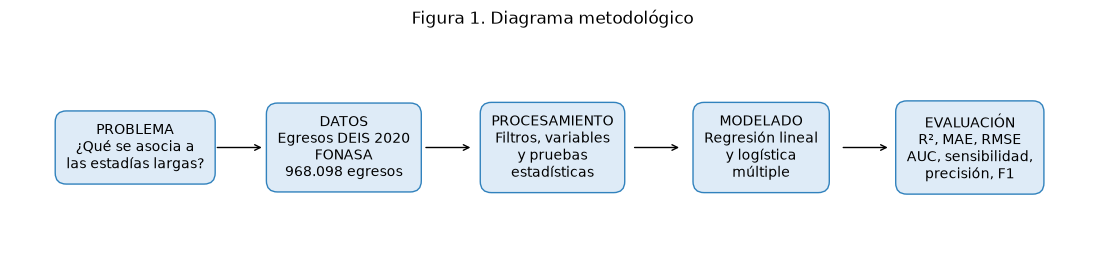

In [1]:
import matplotlib.pyplot as plt

etapas = ["PROBLEMA\n¿Qué se asocia a\nlas estadías largas?",
          "DATOS\nEgresos DEIS 2020\nFONASA\n968.098 egresos",
          "PROCESAMIENTO\nFiltros, variables\ny pruebas\nestadísticas",
          "MODELADO\nRegresión lineal\ny logística\nmúltiple",
          "EVALUACIÓN\nR², MAE, RMSE\nAUC, sensibilidad,\nprecisión, F1"]

fig, ax = plt.subplots(figsize=(14, 3))
ax.axis("off")
for i, texto in enumerate(etapas):
    ax.text(i, 0, texto, ha="center", va="center", fontsize=10,
            bbox=dict(boxstyle="round,pad=0.8", facecolor="#deebf7", edgecolor="#3182bd"))
    if i < len(etapas) - 1:
        ax.annotate("", xy=(i + 0.62, 0), xytext=(i + 0.38, 0), arrowprops=dict(arrowstyle="->"))
ax.set_xlim(-0.6, len(etapas) - 0.4)
ax.set_ylim(-1, 1)
ax.set_title("Figura 1. Diagrama metodológico")
plt.show()

## 5. Análisis de relaciones entre variables

### Paso 1: cargar los datos

Leemos el archivo del DEIS directamente desde el zip y aplicamos los dos filtros de la metodología: solo FONASA y estadías de hasta 365 días.

In [2]:
import warnings
import zipfile
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.diagnostic import lilliefors
from statsmodels.stats.multitest import multipletests
warnings.filterwarnings("ignore")

with zipfile.ZipFile("data/raw/EGRESOS_2020.zip") as z:
    df = pd.read_csv(z.open("EGRE_DATOS_ABIERTOS_2020.csv"), sep=";", encoding="cp1252", dtype=str)
print("Egresos 2020:", len(df))

df = df[df["PREVISION"] == "1"]                      # solo FONASA
df["dias_estada"] = pd.to_numeric(df["DIAS_ESTADA"])
df = df[df["dias_estada"] <= 365].copy()             # quitamos errores de registro
print("Egresos FONASA con estada <= 365 días:", len(df))

Egresos 2020: 1330477


Egresos FONASA con estada <= 365 días: 968098


### Paso 2: construir las variables

Pasamos cada columna original a la variable que usaremos. Para la edad usamos el punto medio de cada tramo, y el capítulo CIE-10 lo obtenemos del diccionario del DEIS.

In [3]:
edad_media = {"menor de un año": 0.5, "1 a 9": 5, "10 a 19": 14.5, "20 a 29": 24.5, "30 a 39": 34.5,
              "40 a 49": 44.5, "50 a 59": 54.5, "60 a 69": 64.5, "70 a 79": 74.5, "80 a 89": 84.5,
              "90 y más": 92.5}
cie = pd.read_excel("data/raw/x2020/Diccionario BD egresos hospitalario.xlsx", "codigo CIE-10", header=8)
cie.columns = cie.columns.str.strip()

df["prolongada"] = np.where(df["dias_estada"] > 15, "Sí", "No")
df["edad"] = df["GRUPO_EDAD"].map(edad_media)
df["tramo_edad"] = df["GRUPO_EDAD"]
df["sexo"] = df["SEXO"]
df["nacionalidad"] = df["GLOSA_PAIS_ORIGEN"]
df["etnia"] = np.where(df["ETNIA"].str.startswith("Si"), "Sí", "No")
df["capitulo"] = df["DIAG1"].map(dict(zip(cie["CODIGO SUBCATEGORIA"], cie["CAPITULO"])))
df["capitulo"] = df["capitulo"].fillna(df["DIAG1"].str[:3].map(dict(zip(cie["CODIGO CATEGORIA"], cie["CAPITULO"]))))
df["cirugia"] = df["INTERV_Q"].map({"1": "Sí", "2": "No"})
df["establecimiento"] = np.where(df["PERTENENCIA_ESTABLECIMIENTO_SALUD"].str.startswith("Pert"), "SNSS", "No SNSS")
df["region"] = df["GLOSA_REGION_RESIDENCIA"]

variables = ["dias_estada", "prolongada", "edad", "sexo", "nacionalidad", "etnia",
             "capitulo", "cirugia", "establecimiento", "region"]
print("Valores faltantes:", df[variables].isna().sum().sum())
df[variables].head()

Valores faltantes: 0


,dias_estada,prolongada,edad,sexo,nacionalidad,etnia,capitulo,cirugia,establecimiento,region
0,1,No,5.0,HOMBRE,Chileno,No,Q00-Q99,Sí,No SNSS,De Tarapacá
1,1,No,5.0,HOMBRE,Chileno,No,Q00-Q99,Sí,No SNSS,De Tarapacá
2,1,No,5.0,HOMBRE,Chileno,No,Z00-Z99,Sí,No SNSS,De Tarapacá
3,1,No,5.0,HOMBRE,Chileno,No,N00-N99,Sí,No SNSS,De Tarapacá
4,1,No,5.0,HOMBRE,Chileno,No,N00-N99,Sí,No SNSS,De Tarapacá


Revisamos cómo se distribuye la duración y cuánto pesan las estadías prolongadas:

In [4]:
largas = df["prolongada"] == "Sí"
print("Media de días:", round(df["dias_estada"].mean(), 1))
print("Mediana de días:", df["dias_estada"].median())
print("Percentil 90:", df["dias_estada"].quantile(0.9))
print("% de egresos prolongados:", round(100 * largas.mean(), 1))
print("% de días-cama que usan:", round(100 * df.loc[largas, "dias_estada"].sum() / df["dias_estada"].sum(), 1))

Media de días: 6.7
Mediana de días: 3.0
Percentil 90: 15.0
% de egresos prolongados: 9.4
% de días-cama que usan: 47.1


La mediana es de 3 días, pero la media es más del doble (6,7), lo que ya indica una cola larga. El 9,4 % de los egresos son prolongados y usan el 47,1 % de los días-cama.

**Cómo leer los resultados de la sección 5.** Usamos α = 0,05. Con casi un millón de datos casi todo será significativo, así que además miramos el **tamaño del efecto** con los umbrales de Cohen (1988):

| Medida | Pequeño | Mediano | Grande |
|---|---|---|---|
| ρ de Spearman, r, V de Cramér | 0,1 | 0,3 | 0,5 |
| ε² (Kruskal-Wallis) | 0,01 | 0,06 | 0,14 |

Cuando un valor-p aparece como 0 (o con un exponente como e-98), es tan pequeño que lo reportamos como **p < 0,001**.

### 5.1 Pruebas de normalidad

Antes de elegir las pruebas, revisamos si las variables numéricas (días de estada y edad) son normales.

- **H₀:** la variable es normal.
- **H₁:** la variable no es normal.

Aplicamos tres pruebas. Shapiro-Wilk usa una muestra de 5.000 egresos, porque con más datos su valor-p deja de ser exacto.

In [5]:
resultados = []
for var in ["dias_estada", "edad"]:
    x = df[var].astype(float)
    sw = stats.shapiro(x.sample(5000, random_state=1))
    ks_d, ks_p = lilliefors(x, pvalmethod="approx")
    ad = stats.anderson(x, dist="norm")
    resultados.append({"variable": var,
                       "Shapiro-Wilk W": sw.statistic, "p SW": sw.pvalue,
                       "Lilliefors D": ks_d, "p KS": ks_p,
                       "Anderson-Darling A²": ad.statistic, "valor crítico AD 5 %": ad.critical_values[2]})
pd.DataFrame(resultados).round(3)

,variable,Shapiro-Wilk W,p SW,Lilliefors D,p KS,Anderson-Darling A²,valor crítico AD 5 %
0,dias_estada,0.442,0.0,0.328,0.0,150920.967,0.752
1,edad,0.957,0.0,0.129,0.0,13546.111,0.752


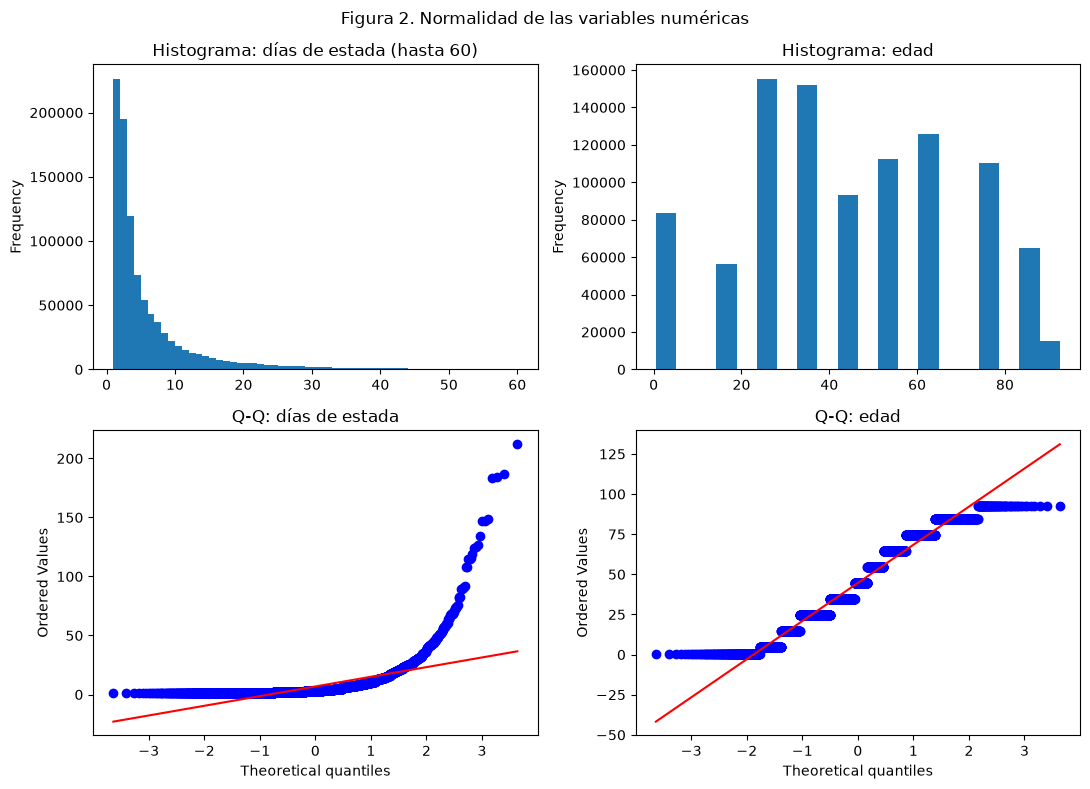

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
df["dias_estada"].plot(kind="hist", bins=range(1, 61), ax=ax[0, 0], title="Histograma: días de estada (hasta 60)")
df["edad"].plot(kind="hist", bins=20, ax=ax[0, 1], title="Histograma: edad")
stats.probplot(df["dias_estada"].sample(5000, random_state=1), plot=ax[1, 0])
ax[1, 0].set_title("Q-Q: días de estada")
stats.probplot(df["edad"].sample(5000, random_state=1), plot=ax[1, 1])
ax[1, 1].set_title("Q-Q: edad")
fig.suptitle("Figura 2. Normalidad de las variables numéricas")
plt.tight_layout()
plt.show()

**Resultado:** las tres pruebas dan p < 0,001 y el estadístico de Anderson-Darling supera su valor crítico, así que **rechazamos la normalidad** en ambas variables.

- Los días tienen una cola larga a la derecha: en el Q-Q los puntos se alejan de la recta arriba.
- La edad viene en tramos, por eso el Q-Q forma escalones.

**Decisión:** desde aquí usamos pruebas **no paramétricas**: Spearman en vez de Pearson, Mann-Whitney en vez de t de Student y Kruskal-Wallis en vez de ANOVA.

### 5.2 Numérica vs. numérica: edad y días de estada

Como no hay normalidad, usamos la **correlación de Spearman**.

- **H₀:** ρ = 0 (no hay relación).
- **H₁:** ρ ≠ 0.

rho de Spearman: 0.25 | valor-p: 0.0


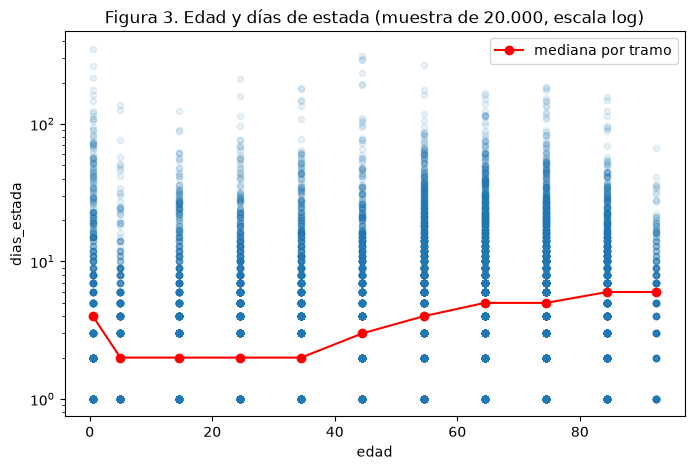

In [7]:
rho, p = stats.spearmanr(df["edad"], df["dias_estada"])
print("rho de Spearman:", round(rho, 3), "| valor-p:", p)

muestra = df.sample(20000, random_state=1)
ax = muestra.plot(kind="scatter", x="edad", y="dias_estada", alpha=0.1, logy=True, figsize=(8, 5))
df.groupby("edad")["dias_estada"].median().plot(ax=ax, color="red", marker="o", label="mediana por tramo")
ax.legend()
ax.set_title("Figura 3. Edad y días de estada (muestra de 20.000, escala log)")
plt.show()

**Resultado:** ρ = 0,25 y p < 0,001. **Rechazamos H₀**: a mayor edad, la estadía tiende a ser más larga, pero el efecto es **pequeño**. La línea roja muestra que la mediana sube de 2 días en adultos jóvenes a 6 días desde los 80 años. Los menores de un año son una excepción, con 4 días.

### 5.3 Numérica vs. categórica: días de estada según cada factor

Como los días no son normales:

- Para factores con **2 grupos** usamos **Mann-Whitney U**, y el efecto se mide con la correlación biserial *r*.
- Para factores con **más de 2 grupos** usamos **Kruskal-Wallis**, y el efecto se mide con ε².

Hipótesis para cada factor:

- **H₀:** los días se distribuyen igual en todos los grupos.
- **H₁:** al menos un grupo es distinto.

In [8]:
filas = []
for var in ["sexo", "nacionalidad", "etnia", "cirugia", "establecimiento"]:
    g1, g2 = sorted(df[var].unique())
    x1 = df.loc[df[var] == g1, "dias_estada"]
    x2 = df.loc[df[var] == g2, "dias_estada"]
    u, p = stats.mannwhitneyu(x1, x2)
    r = 2 * u / (len(x1) * len(x2)) - 1              # r > 0: el grupo 1 tiene estadías más largas
    filas.append({"variable": var, "prueba": "Mann-Whitney", "grupos": f"{g1} / {g2}",
                  "medianas": f"{x1.median():.0f} / {x2.median():.0f}", "valor-p": p, "efecto": round(r, 2)})

for var in ["capitulo", "region"]:
    grupos = [g["dias_estada"] for _, g in df.groupby(var)]
    h, p = stats.kruskal(*grupos)
    medianas = df.groupby(var)["dias_estada"].median()
    filas.append({"variable": var, "prueba": "Kruskal-Wallis", "grupos": f"{len(grupos)} grupos",
                  "medianas": f"{medianas.min():.0f} a {medianas.max():.0f}", "valor-p": p,
                  "efecto": round(h / (len(df) - 1), 3)})
pd.DataFrame(filas)

,variable,prueba,grupos,medianas,valor-p,efecto
0,sexo,Mann-Whitney,HOMBRE / MUJER,4 / 3,0.000000e+00,0.140
1,nacionalidad,Mann-Whitney,Chileno / extranjero,3 / 3,8.472698e-98,0.060
2,etnia,Mann-Whitney,No / Sí,3 / 3,4.723463e-10,-0.020
3,cirugia,Mann-Whitney,No / Sí,4 / 2,0.000000e+00,0.220
4,establecimiento,Mann-Whitney,No SNSS / SNSS,2 / 3,0.000000e+00,-0.370
5,capitulo,Kruskal-Wallis,21 grupos,1 a 9,0.000000e+00,0.120
6,region,Kruskal-Wallis,16 grupos,2 a 4,0.000000e+00,0.002


Kruskal-Wallis solo dice que *algún* grupo es distinto. Para saber cuáles, hacemos una prueba **post-hoc**: comparamos cada par de grupos con Mann-Whitney y corregimos los valores-p con el método de Holm, porque son muchas comparaciones.

In [9]:
for var in ["capitulo", "region"]:
    nombres = sorted(df[var].unique())
    pares, valores_p = [], []
    for i, a in enumerate(nombres):
        for b in nombres[i + 1:]:
            p = stats.mannwhitneyu(df.loc[df[var] == a, "dias_estada"], df.loc[df[var] == b, "dias_estada"]).pvalue
            pares.append((a, b))
            valores_p.append(p)
    rechaza = multipletests(valores_p, method="holm")[0]
    print(f"{var}: {rechaza.sum()} de {len(pares)} pares son distintos (Holm, α = 0,05)")

capitulo: 202 de 210 pares son distintos (Holm, α = 0,05)


region: 104 de 120 pares son distintos (Holm, α = 0,05)


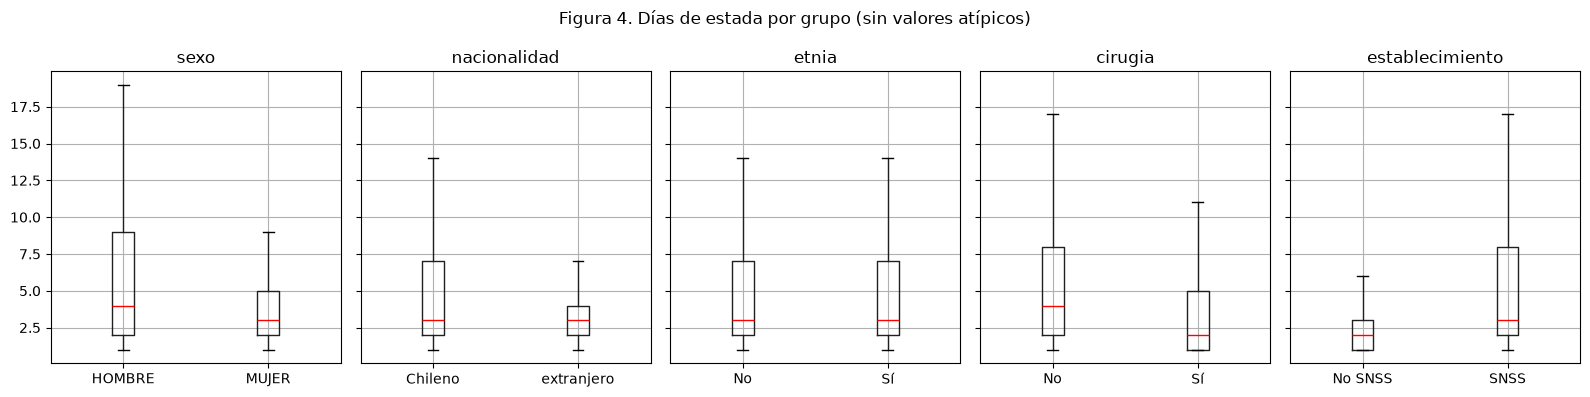

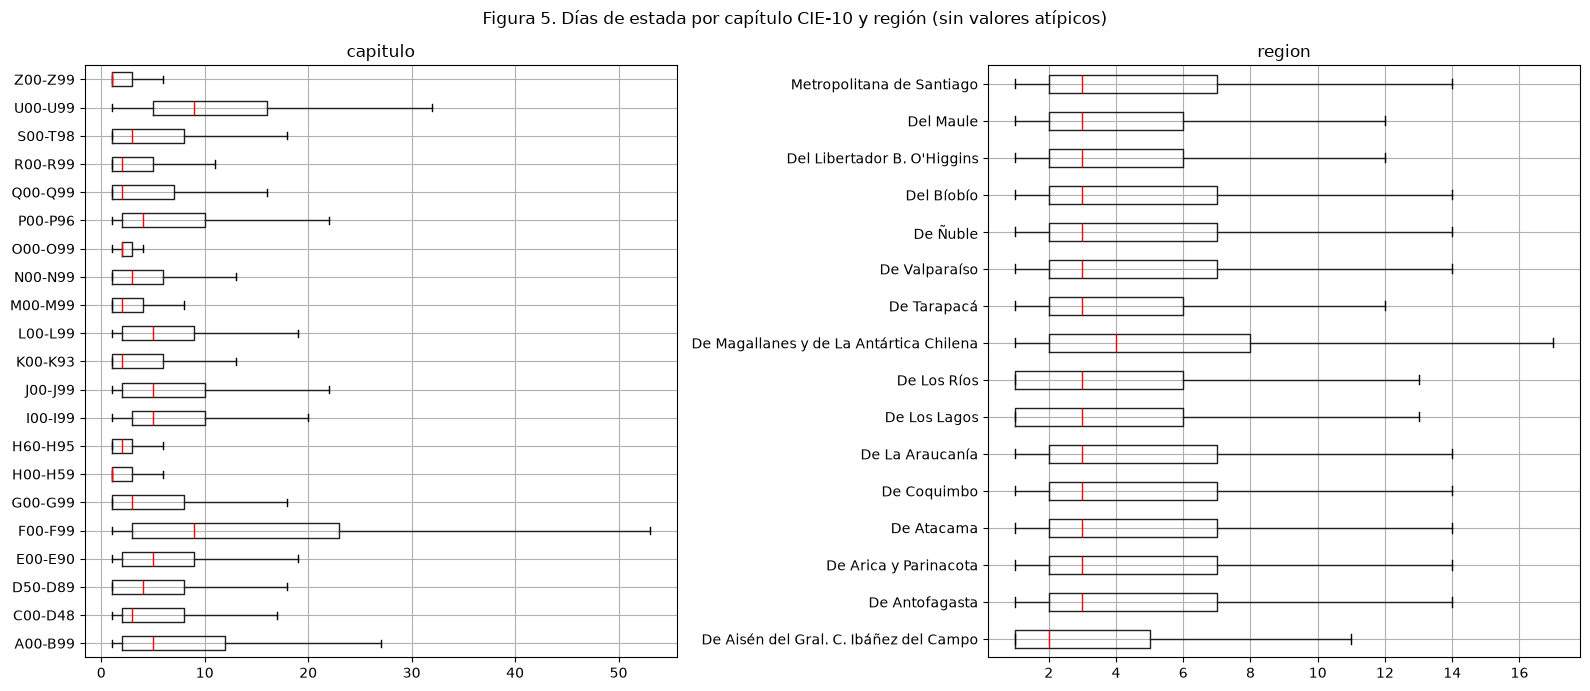

In [10]:
fig, ax = plt.subplots(1, 5, figsize=(16, 4), sharey=True)
for i, var in enumerate(["sexo", "nacionalidad", "etnia", "cirugia", "establecimiento"]):
    df.boxplot(column="dias_estada", by=var, ax=ax[i], showfliers=False, color=dict(medians="red"))
    ax[i].set_title(var)
    ax[i].set_xlabel("")
fig.suptitle("Figura 4. Días de estada por grupo (sin valores atípicos)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for i, var in enumerate(["capitulo", "region"]):
    df.boxplot(column="dias_estada", by=var, ax=ax[i], showfliers=False, vert=False, color=dict(medians="red"))
    ax[i].set_title(var)
    ax[i].set_ylabel("")
fig.suptitle("Figura 5. Días de estada por capítulo CIE-10 y región (sin valores atípicos)")
plt.tight_layout()
plt.show()

**Resultado:** todas las pruebas dan p < 0,001, así que **rechazamos H₀ en todos los factores**. Como era de esperar con tantos datos, lo que separa a los factores es el tamaño del efecto:

| Factor | Efecto | Qué significa |
|---|---|---|
| Establecimiento | r = −0,37 (mediano) | En los establecimientos SNSS las estadías son más largas que en los no SNSS |
| Capítulo CIE-10 | ε² = 0,12 (mediano) | La mediana va de 1 día (controles, ojo) a 9 días (trastornos mentales, COVID-19) |
| Cirugía | r = 0,22 (pequeño) | Sin cirugía se está más tiempo (mediana 4 vs. 2 días) |
| Sexo | r = 0,14 (pequeño) | Los hombres están un día más (4 vs. 3); los partos, cortos, bajan la mediana de las mujeres |
| Nacionalidad, etnia, región | despreciable | Son significativos solo por el tamaño de la muestra |

En el post-hoc, 202 de 210 pares de capítulos y 104 de 120 pares de regiones difieren. En las regiones, sin embargo, el efecto global es despreciable (ε² = 0,002).

### 5.4 Categórica vs. categórica: estadía prolongada según cada factor

Usamos **chi-cuadrado de independencia** entre cada factor y la estadía prolongada (Sí/No). Para la edad usamos sus 11 tramos. La fuerza de la asociación se mide con la **V de Cramér**.

- **H₀:** el factor y la estadía prolongada son independientes.
- **H₁:** están asociados.

El chi-cuadrado exige frecuencias esperadas de al menos 5; si no se cumpliera en una tabla 2×2, usaríamos el test exacto de Fisher.

In [11]:
filas = []
for var in ["tramo_edad", "sexo", "nacionalidad", "etnia", "capitulo", "cirugia", "establecimiento", "region"]:
    tabla = pd.crosstab(df[var], df["prolongada"])
    chi2, p, gl, esperadas = stats.chi2_contingency(tabla)
    v = np.sqrt(chi2 / (len(df) * (min(tabla.shape) - 1)))
    pct = 100 * tabla["Sí"] / tabla.sum(axis=1)
    filas.append({"variable": var, "chi²": round(chi2), "gl": gl, "valor-p": p, "V de Cramér": round(v, 3),
                  "% prolongadas (mín - máx)": f"{pct.min():.1f} - {pct.max():.1f}",
                  "frec. esperada mínima": round(esperadas.min())})
pd.DataFrame(filas)

,variable,chi²,gl,valor-p,V de Cramér,% prolongadas (mín - máx),frec. esperada mínima
0,tramo_edad,26265,10,0.000000e+00,0.165,3.5 - 15.4,1408
1,sexo,10332,1,0.000000e+00,0.103,6.9 - 13.1,36376
2,nacionalidad,642,1,1.294187e-141,0.026,5.7 - 9.5,3599
3,etnia,14,1,1.932279e-04,0.004,8.6 - 9.4,1987
4,capitulo,60840,20,0.000000e+00,0.251,0.9 - 35.6,175
5,cirugia,2749,1,0.000000e+00,0.053,7.4 - 10.6,34007
6,establecimiento,6897,1,0.000000e+00,0.084,4.2 - 10.6,16504
7,region,2343,15,0.000000e+00,0.049,6.6 - 10.9,674


Ejemplo de una tabla de contingencia (establecimiento vs. estadía prolongada):

In [12]:
tabla = pd.crosstab(df["establecimiento"], df["prolongada"], margins=True)
tabla["% prolongadas"] = (100 * tabla["Sí"] / tabla["All"]).round(1)
tabla

prolongada,No,Sí,All,% prolongadas
establecimiento,,,,
No SNSS,168437,7316,175753,4.2
SNSS,708752,83593,792345,10.6
All,877189,90909,968098,9.4


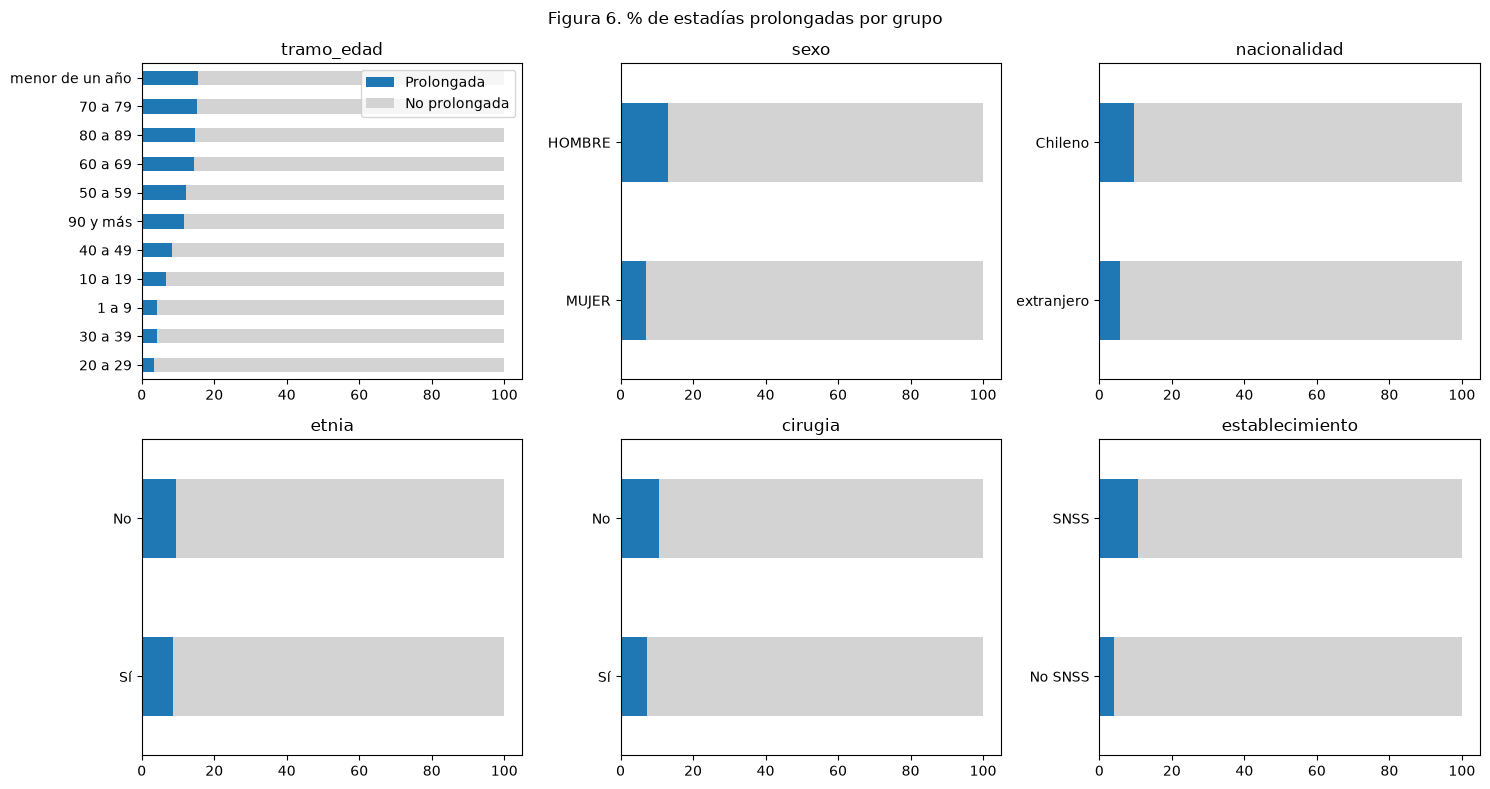

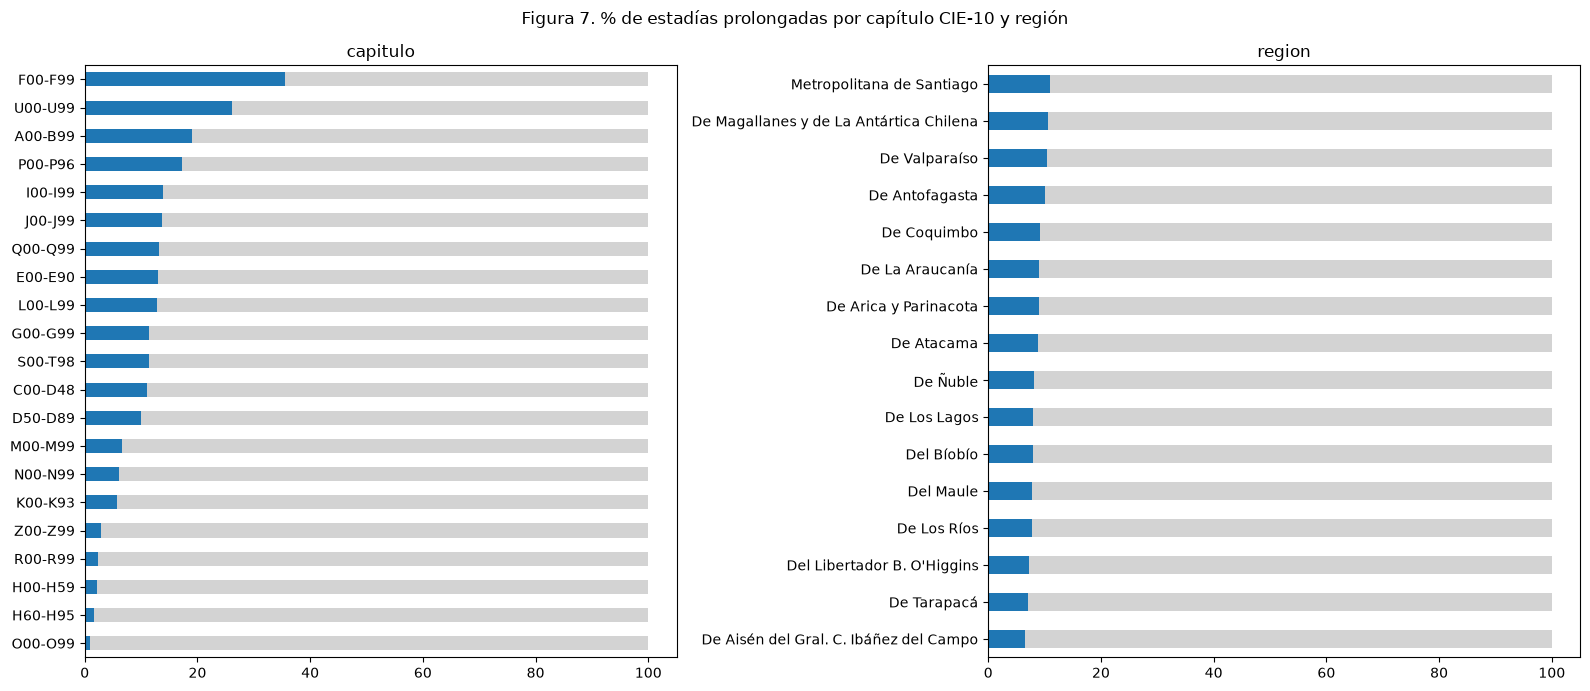

In [13]:
def barras(var, ax):
    pct = pd.crosstab(df[var], df["prolongada"], normalize="index")[["Sí", "No"]] * 100
    pct.sort_values("Sí").plot(kind="barh", stacked=True, ax=ax, legend=False, color=["tab:blue", "lightgray"])
    ax.set_title(var)
    ax.set_ylabel("")

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for i, var in enumerate(["tramo_edad", "sexo", "nacionalidad", "etnia", "cirugia", "establecimiento"]):
    barras(var, ax.flat[i])
ax.flat[0].legend(["Prolongada", "No prolongada"])
fig.suptitle("Figura 6. % de estadías prolongadas por grupo")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
barras("capitulo", ax[0])
barras("region", ax[1])
fig.suptitle("Figura 7. % de estadías prolongadas por capítulo CIE-10 y región")
plt.tight_layout()
plt.show()

**Resultado:** todas las frecuencias esperadas superan 5 (la menor es 175), así que el chi-cuadrado es válido. Todas las pruebas dan p < 0,001: **rechazamos H₀ en todos los factores**.

| Factor | V de Cramér | Qué significa |
|---|---|---|
| Capítulo CIE-10 | 0,25 (pequeño) | De 0,9 % prolongadas (partos) a 35,6 % (trastornos mentales) |
| Tramo de edad | 0,17 (pequeño) | Forma de U: 15,4 % en menores de un año, 3,5 % entre 20 y 29 años y 15,4 % entre 70 y 79 |
| Sexo | 0,10 (pequeño) | 13,1 % en hombres y 6,9 % en mujeres |
| Establecimiento | 0,08 (despreciable) | 10,6 % en SNSS y 4,2 % en no SNSS |
| Cirugía, región, nacionalidad, etnia | < 0,06 (despreciable) | Diferencias de pocos puntos porcentuales |

### 5.5 Tabla resumen

| Variable 1 | Variable 2 | Test aplicado | Valor-p | Conclusión |
|---|---|---|---|---|
| Días de estada | Normalidad | Shapiro-Wilk, Lilliefors, Anderson-Darling | < 0,001 | No es normal: usamos pruebas no paramétricas |
| Edad | Normalidad | Shapiro-Wilk, Lilliefors, Anderson-Darling | < 0,001 | No es normal: usamos pruebas no paramétricas |
| Edad | Días de estada | Spearman | < 0,001 | Más edad, algo más de días (ρ = 0,25, pequeño) |
| Sexo | Días de estada | Mann-Whitney U | < 0,001 | Hombres con estadías más largas (r = 0,14, pequeño) |
| Nacionalidad | Días de estada | Mann-Whitney U | < 0,001 | Efecto despreciable (r = 0,06) |
| Etnia | Días de estada | Mann-Whitney U | < 0,001 | Efecto despreciable (r = −0,02) |
| Cirugía | Días de estada | Mann-Whitney U | < 0,001 | Sin cirugía, estadías más largas (r = 0,22, pequeño) |
| Establecimiento | Días de estada | Mann-Whitney U | < 0,001 | SNSS con estadías más largas (r = −0,37, mediano) |
| Capítulo CIE-10 | Días de estada | Kruskal-Wallis + post-hoc | < 0,001 | Mediana de 1 a 9 días según capítulo (ε² = 0,12, mediano) |
| Región | Días de estada | Kruskal-Wallis + post-hoc | < 0,001 | Efecto despreciable (ε² = 0,002) |
| Tramo de edad | Estadía prolongada | Chi-cuadrado | < 0,001 | Forma de U (V = 0,17, pequeño) |
| Sexo | Estadía prolongada | Chi-cuadrado | < 0,001 | 13,1 % hombres vs. 6,9 % mujeres (V = 0,10, pequeño) |
| Nacionalidad | Estadía prolongada | Chi-cuadrado | < 0,001 | Efecto despreciable (V = 0,03) |
| Etnia | Estadía prolongada | Chi-cuadrado | < 0,001 | Efecto despreciable (V = 0,004) |
| Capítulo CIE-10 | Estadía prolongada | Chi-cuadrado | < 0,001 | De 0,9 % a 35,6 % (V = 0,25, pequeño) |
| Cirugía | Estadía prolongada | Chi-cuadrado | < 0,001 | Efecto despreciable (V = 0,05) |
| Establecimiento | Estadía prolongada | Chi-cuadrado | < 0,001 | 10,6 % vs. 4,2 % (V = 0,08, despreciable) |
| Región | Estadía prolongada | Chi-cuadrado | < 0,001 | Efecto despreciable (V = 0,05) |

### Conclusión

Todas las pruebas rechazan H₀, así que **rechazamos la hipótesis nula general**. Según el tamaño del efecto:

- **H1a (clínicos): se cumple.** El capítulo CIE-10 es el factor más importante. La cirugía cambia los días, pero casi no cambia la proporción de estadías prolongadas.
- **H1b (demográficos): se cumple para edad y sexo**, con efectos pequeños. Nacionalidad y etnia no tienen un efecto relevante.
- **H1c (sistema de salud): se cumple para el tipo de establecimiento**, con efecto mediano sobre los días. La región no tiene un efecto relevante.

Estas son relaciones de a pares. En el Avance 2, la regresión múltiple mostrará qué factores siguen importando cuando se consideran todos a la vez; por ejemplo, si la diferencia por sexo se mantiene al controlar por diagnóstico.

## Referencias

1. Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2.ª ed.). Lawrence Erlbaum Associates.
2. Fetter, R. B., Shin, Y., Freeman, J. L., Averill, R. F., & Thompson, J. D. (1980). Case mix definition by diagnosis-related groups. *Medical Care, 18*(2 Suppl.), 1–53.
3. Freitas, A., Silva-Costa, T., Lopes, F., Garcia-Lema, I., Teixeira-Pinto, A., Brazdil, P., & Costa-Pereira, A. (2012). Factors influencing hospital high length of stay outliers. *BMC Health Services Research, 12*, 265. https://doi.org/10.1186/1472-6963-12-265
4. Lequertier, V., Wang, T., Fondrevelle, J., Augusto, V., & Duclos, A. (2021). Hospital length of stay prediction methods: A systematic review. *Medical Care, 59*(10), 929–938. https://doi.org/10.1097/MLR.0000000000001596
5. Lin, M., Lucas, H. C., & Shmueli, G. (2013). Too big to fail: Large samples and the p-value problem. *Information Systems Research, 24*(4), 906–917. https://doi.org/10.1287/isre.2013.0480
6. Olivares-Tirado, P. (2020). *Hospitalización social en adultos mayores en el sistema de salud de Chile* [Documento de trabajo]. Superintendencia de Salud.